# 5.6 Statistical Errors

**Goal:** separate error rates, effect sizes, power, and multiple-comparison guarantees.

**Prerequisites:** Modules 0–4 and earlier notebooks in this module; advanced notebooks also build on earlier modules 5–8. Read the section assumptions before using a method.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. Install in your chosen environment with `python3 -m pip install numpy scipy matplotlib`, then open in JupyterLab or VS Code with a Python kernel. Use **Restart Kernel and Run All**. Each notebook is self-contained, includes saved outputs, uses synthetic data and a fixed local random seed, and needs no downloads. Numerical simulations illustrate results; they do not prove them or validate real-world assumptions.

## Module navigation

1. [Sampling Techniques](1_Sampling-Techniques.ipynb)
2. [Sampling Concepts](2_Sampling-Concepts.ipynb)
3. [Estimation Theory](3_Estimation-Theory.ipynb)
4. [Confidence Intervals](4_Confidence-Intervals.ipynb)
5. [Hypothesis Testing](5_Hypothesis-Testing.ipynb)
6. [Statistical Errors](6_Statistical-Errors.ipynb)
7. [Statistical Tests](7_Statistical-Tests.ipynb)

## Learning route

Read each definition and assumption, work through its calculation, run the code, then attempt the practice before viewing the solutions. Distinguish descriptive association, causal inference, and predictive evaluation throughout.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, special, linalg
rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12, "font.size": 10})

## 1. Type I Error and Type II Error

Type I error rejects a true null; its controlled probability is α under the stated null model. Type II error fails to reject a false null; its probability β depends on the specific alternative, sample size, design, noise, and rejection rule. These are long-run procedure properties, not labels proving whether one observed conclusion is correct.

A false positive in a hypothesis test differs from a false positive label prediction: the tested units are hypotheses rather than individual classified cases. A small p-value does not directly reveal the probability that a reported finding is false.

## 2. Statistical Power and Effect Size

Power is 1−β at a stated alternative. Larger independent samples, lower noise, larger true effects, and a directional rejection region can raise power, with tradeoffs. Plan power for a **minimum practically relevant effect**, not the effect observed after running the study.

Effect size can be raw (minutes saved, percentage-point difference) or standardized. Cohen's d for two groups typically divides a mean difference by a specified SD; paired standardized effects may use the SD of differences, giving another quantity. Report the denominator convention. Statistical significance depends strongly on precision and does not measure importance.

**Worked example:** a two-sided known-variance mean test has alternative Z∼Normal(δ√n/σ,1). Its power is the alternative probability outside ±z₁₋α/₂. Raw δ=0.5 with σ=1 corresponds to a standardized effect 0.5.

n: 10 power for delta=.5: 0.35260808244470254
n: 30 power for delta=.5: 0.7819079987319799
n: 100 power for delta=.5: 0.9988172507035044


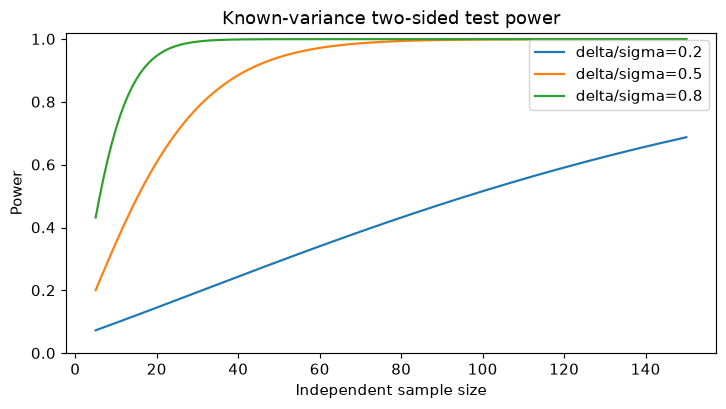

In [2]:
def z_power(n,delta,sigma=1,alpha=.05):
    threshold=stats.norm.ppf(1-alpha/2);shift=delta*np.sqrt(n)/sigma
    return stats.norm.cdf(-threshold,loc=shift)+stats.norm.sf(threshold,loc=shift)
for n in [10,30,100]: print("n:",n,"power for delta=.5:",z_power(n,.5))
ns=np.arange(5,151)
fig,ax=plt.subplots()
for effect in [.2,.5,.8]: ax.plot(ns,[z_power(n,effect) for n in ns],label=f"delta/sigma={effect}")
ax.set(title="Known-variance two-sided test power",xlabel="Independent sample size",ylabel="Power",ylim=(0,1.02))
ax.legend();fig.tight_layout();plt.show()

## 3. Multiple Testing Problem and Bonferroni Correction

With m independent true-null tests each at α, the chance of at least one false rejection is $1-(1-α)^m$. At m=20 and α=.05 it is about .642. Independence is needed for this exact expression, not for the Bonferroni bound.

Bonferroni controls **familywise error rate (FWER)** by testing each hypothesis at α/m or using adjusted p=min(mp,1). Its union-bound guarantee holds under arbitrary dependence when individual p-values are valid. It can be conservative, especially with many correlated tests. Define the family according to the scientific claim rather than excluding inconvenient analyses after the fact.

In [3]:
pvalues=np.array([.001,.009,.018,.04,.2,.8])
bonf=np.minimum(len(pvalues)*pvalues,1)
print("20-test independent FWER:",1-.95**20)
print("Raw p:",pvalues,"Bonferroni adjusted:",bonf)

20-test independent FWER: 0.6415140775914581
Raw p: [0.001 0.009 0.018 0.04  0.2   0.8  ] Bonferroni adjusted: [0.006 0.054 0.108 0.24  1.    1.   ]


## 4. False Discovery Rate

If V is the number of false rejections and R total rejections, **FDR** is $E[V/\max(R,1)]$. This is not the probability of at least one error (FWER) and does not mean every rejected hypothesis has the same posterior false-discovery probability.

Benjamini–Hochberg (BH) orders p-values p₍₁₎≤…≤p₍ₘ₎, finds the largest k with p₍ₖ₎≤qk/m, and rejects that prefix. Its usual FDR control requires valid p-values and independence or specified positive-dependence conditions. Benjamini–Yekutieli (BY) is more conservative but supports arbitrary dependence. Neither adjustment repairs biased data or invalid single-test p-values.

**Worked example:** compare BH-adjusted and Bonferroni-adjusted p-values for six hypotheses. BH can yield more discoveries because it targets a different error criterion, not because it removes multiplicity. The [SciPy FDR reference](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.false_discovery_control.html) documents BH/BY choices.

In [4]:
bh=stats.false_discovery_control(pvalues,method="bh")
by=stats.false_discovery_control(pvalues,method="by")
print("BH adjusted:",bh,"rejections:",bh<=.05)
print("BY adjusted:",by)
assert np.all(bh>=pvalues-1e-12)

BH adjusted: [0.006 0.027 0.036 0.06  0.24  0.8  ] rejections: [ True  True  True False False False]
BY adjusted: [0.0147  0.06615 0.0882  0.147   0.588   1.     ]


## AI/ML application and interpretation

Large-scale feature screening and repeated model comparisons create multiplicity. Choose FWER or FDR based on the use of discoveries, retain independent validation, and report raw effect magnitudes and uncertainty. Retrospective “observed power” based on the observed effect adds little beyond the p-value and is not a substitute for prospective planning.

## Practice

1. At a specified alternative, β=.2. What is power?
2. For 100 tests, what Bonferroni threshold controls FWER at .05?
3. Does FDR=.05 guarantee no false findings in a realized study?
4. Why can a tiny effect be significant in a huge sample?
5. Does Bonferroni require independence? Does standard BH work under every dependency pattern?

## Solutions

1. .8.
2. .05/100=.0005 per test, with valid p-values.
3. No. It controls an expectation of a false-discovery proportion under its assumptions, not each realized collection.
4. Standard errors can be very small, so statistical detectability need not imply practical value.
5. Bonferroni uses a union bound and does not require independence. Standard BH needs its validity conditions; BY handles arbitrary dependence more conservatively.

**Readiness check:** identify the estimand, independent unit, assumptions, uncertainty source, and an important failure mode before using these methods.

**Next:** [Continue studying](7_Statistical-Tests.ipynb).